# TP pratique — Évaluation des modèles NLP
## 3 tâches : Résumé automatique • Question Answering • Génération de texte

**Objectif :** comprendre, calculer et interpréter les métriques avec de vrais exemples en français.

| Partie | Métriques |
|:--|:--|
| 1. Résumé automatique | ROUGE-1, ROUGE-2, ROUGE-L, BLEU-2, BERTScore (option) |
| 2. Question Answering | Exact Match, Token F1, similarité sémantique (option), Faithfulness |
| 3. Text Generation | Perplexity, Distinct-1, Distinct-2, Self-BLEU-2, MAUVE (option) |
| Bonus | Évaluation humaine : fluidité, cohérence, pertinence, factualité |

**Mode de fonctionnement :** les calculs fondamentaux sont faits en Python pur, sans téléchargement de modèle. Les sections **OPTIONNELLES** effectuent de vrais calculs avec des modèles préentraînés et nécessitent Internet lors de leur première utilisation. Cela permet de faire le TP sur un ordinateur modeste.

> Les données sont pédagogiques et fictives. Une comparaison scientifique entre modèles exige un corpus représentatif, une tokenisation cohérente et un protocole reproductible.

## 0. Préparation
Exécuter les cellules de haut en bas. `RUN_HEAVY = False` par défaut : le notebook est utilisable rapidement sur CPU, sans téléchargement des modèles.

In [1]:
import re, math, statistics
from collections import Counter

RUN_HEAVY = False  # passer à True pour les cellules de modèles préentraînés

def tokens(text):
    """Tokenisation pédagogique en mots ; conserve les accents, supprime la ponctuation."""
    return re.findall(r"[^\W_]+", text.lower(), flags=re.UNICODE)

def ngrams(seq, n):
    return [tuple(seq[i:i+n]) for i in range(max(0, len(seq)-n+1))]

def prf(overlap, candidate_count, reference_count):
    p = overlap / candidate_count if candidate_count else 0.0
    r = overlap / reference_count if reference_count else 0.0
    f1 = (2*p*r/(p+r)) if p+r else 0.0
    return {'precision':p, 'recall':r, 'f1':f1}

def clipped_overlap(candidate_items, reference_items):
    a, b = Counter(candidate_items), Counter(reference_items)
    return sum(min(v, b[k]) for k,v in a.items())

def show_scores(scores):
    for k,v in scores.items():
        print(f'{k:>15}: {v:.4f}')

print('Environnement prêt. Démonstration légère activée :', not RUN_HEAVY)

Environnement prêt. Démonstration légère activée : True


---
# PARTIE 1 — Résumé automatique

**Problème :** comparer un résumé généré par un modèle à un résumé de référence humaine.

- **ROUGE-1** compare les mots.
- **ROUGE-2** compare les bigrammes.
- **ROUGE-L** utilise la plus longue sous-séquence commune (LCS).
- **BLEU** combine des précisions modifiées des n-grammes et une pénalité de longueur.
- **BERTScore** compare des représentations contextualisées (option avancée).

In [2]:
resume_reference = "Le petit chat noir mange une souris dans le jardin"
resume_candidat = "Le chat mange une souris dans le jardin"
print('RÉFÉRENCE :', resume_reference)
print('CANDIDAT  :', resume_candidat)
print('Tokens de référence :', tokens(resume_reference))
print('Tokens du candidat  :', tokens(resume_candidat))

RÉFÉRENCE : Le petit chat noir mange une souris dans le jardin
CANDIDAT  : Le chat mange une souris dans le jardin
Tokens de référence : ['le', 'petit', 'chat', 'noir', 'mange', 'une', 'souris', 'dans', 'le', 'jardin']
Tokens du candidat  : ['le', 'chat', 'mange', 'une', 'souris', 'dans', 'le', 'jardin']


### 1.1 ROUGE-1 et ROUGE-2

\(P=\frac{\text{n-grammes communs}}{\text{n-grammes candidats}}\), \(R=\frac{\text{n-grammes communs}}{\text{n-grammes référence}}\), \(F1=\frac{2PR}{P+R}\).

Le comptage des occurrences utilise une intersection avec multiplicité (un n-gramme répété n'est pas compté au-delà de la référence).

In [3]:
def rouge_n(reference, candidate, n):
    ref = ngrams(tokens(reference),n)
    cand = ngrams(tokens(candidate),n)
    overlap = clipped_overlap(cand,ref)
    return {'n':n, 'common':overlap, 'candidate_total':len(cand),
            'reference_total':len(ref), **prf(overlap,len(cand),len(ref))}

for n_value in (1,2):
    result = rouge_n(resume_reference,resume_candidat,n_value)
    print(f'\nROUGE-{n_value}: {result["common"]} n-grammes communs')
    show_scores({k:result[k] for k in ('precision','recall','f1')})


ROUGE-1: 8 n-grammes communs
      precision: 1.0000
         recall: 0.8000
             f1: 0.8889

ROUGE-2: 5 n-grammes communs
      precision: 0.7143
         recall: 0.5556
             f1: 0.6250


### 1.2 ROUGE-L : plus longue sous-séquence commune
Une sous-séquence conserve l'ordre, mais les mots ne doivent pas être consécutifs.

In [4]:
def lcs_length(a,b):
    dp=[[0]*(len(b)+1) for _ in range(len(a)+1)]
    for i in range(len(a)-1,-1,-1):
        for j in range(len(b)-1,-1,-1):
            dp[i][j] = 1+dp[i+1][j+1] if a[i]==b[j] else max(dp[i+1][j],dp[i][j+1])
    return dp[0][0]

def rouge_l(reference,candidate):
    a,b=tokens(reference),tokens(candidate)
    l=lcs_length(a,b)
    return {'LCS':l, **prf(l,len(b),len(a))}

result_l=rouge_l(resume_reference,resume_candidat)
print('Longueur LCS :',result_l['LCS'])
show_scores({k:result_l[k] for k in ('precision','recall','f1')})

Longueur LCS : 8
      precision: 1.0000
         recall: 0.8000
             f1: 0.8889


### 1.3 BLEU-2

\(BLEU_2=BP\sqrt{p_1p_2}\), avec précision modifiée, écrêtage des répétitions et pénalité de longueur \(BP = 1\) si le candidat est au moins aussi long que la référence ; sinon \(e^{1-r/c}\).

**Remarque :** implémentation pédagogique **sans lissage**, avec **une seule référence**. Un n-gramme absent peut entraîner BLEU = 0.

In [5]:
def bleu_n(candidate, references, max_n=2):
    """BLEU simplifié, avec plusieurs références et clipping, sans smoothing."""
    cand=tokens(candidate)
    refs=[tokens(ref) for ref in references]
    if not cand or not refs: return 0.0, {}
    precisions=[]
    for n in range(1,max_n+1):
        cg=ngrams(cand,n)
        candidates_counts=Counter(cg)
        maxima={}
        for ref in refs:
            counts=Counter(ngrams(ref,n))
            for g,count in counts.items():
                maxima[g]=max(maxima.get(g,0),count)
        good=sum(min(count,maxima.get(g,0)) for g,count in candidates_counts.items())
        precisions.append(good/len(cg) if cg else 0.0)
    c=len(cand)
    lengths=[len(r) for r in refs]
    r=min(lengths,key=lambda v:(abs(v-c),v))
    bp=1 if c>=r else math.exp(1-r/c)
    bleu=bp*math.exp(sum(math.log(p)/max_n for p in precisions)) if all(p>0 for p in precisions) else 0.0
    return bleu,{'BP':bp,**{f'p{i+1}':v for i,v in enumerate(precisions)}}

bleu,detail=bleu_n(resume_candidat,[resume_reference],2)
print('BLEU-2 :',round(bleu,4))
show_scores(detail)

BLEU-2 : 0.6582
             BP: 0.7788
             p1: 1.0000
             p2: 0.7143


### 1.4 Synthèse visuelle des métriques du résumé

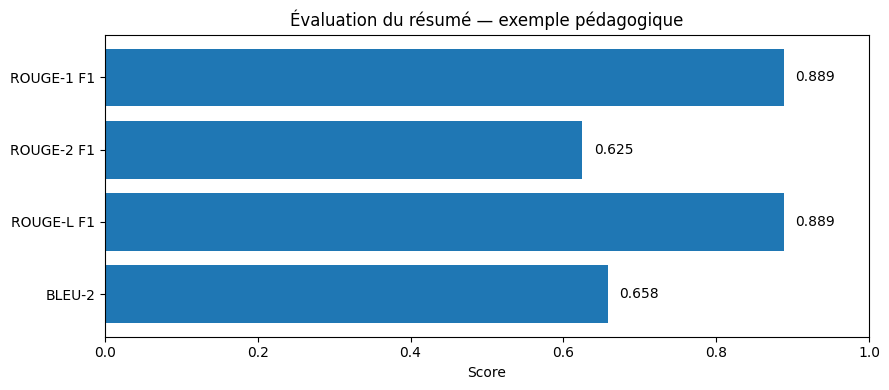

Attention : scores issus de métriques différentes ; ils ne sont pas interchangeables.


In [6]:
import matplotlib.pyplot as plt
resume_scores={
    'ROUGE-1 F1':rouge_n(resume_reference,resume_candidat,1)['f1'],
    'ROUGE-2 F1':rouge_n(resume_reference,resume_candidat,2)['f1'],
    'ROUGE-L F1':rouge_l(resume_reference,resume_candidat)['f1'],
    'BLEU-2':bleu
}
fig,ax=plt.subplots(figsize=(9,4))
ax.barh(list(resume_scores),list(resume_scores.values()))
ax.set(xlim=(0,1),xlabel='Score',title='Évaluation du résumé — exemple pédagogique')
ax.invert_yaxis()
for i,v in enumerate(resume_scores.values()):ax.text(min(v+0.015,.97),i,f'{v:.3f}',va='center')
plt.tight_layout();plt.show()
print('Attention : scores issus de métriques différentes ; ils ne sont pas interchangeables.')

### 1.5 BERTScore réel — OPTIONNEL

Nécessite un téléchargement de modèle et peut être lent sur CPU. La bibliothèque calcule la précision, le rappel et le F1 à partir des embeddings contextualisés.

In [7]:
# Exécuter UNE FOIS si nécessaire :
# %pip install -q bert-score torch transformers
if RUN_HEAVY:
    from bert_score import score as bert_score
    P,R,F=bert_score([resume_candidat],[resume_reference],lang='fr',verbose=False)
    print('BERTScore P/R/F1 :',float(P[0]),float(R[0]),float(F[0]))
else:
    print('BERTScore ignoré (RUN_HEAVY=False). Active-le après installation des dépendances.')

BERTScore ignoré (RUN_HEAVY=False). Active-le après installation des dépendances.


### Exercice 1
Change `resume_candidat` pour une paraphrase (« Le félin dévore un petit rongeur dans le jardin »). Recalcule les métriques. Pourquoi les scores lexicaux baissent-ils même si une partie du sens est conservée ?

---
# PARTIE 2 — Question Answering (QA)

**Problème :** comparer une réponse prédite à une réponse attendue, et vérifier éventuellement que les affirmations sont appuyées par le contexte.

Pour illustrer fidèlement une évaluation, nous distinguons **Exact Match**, **Token F1**, **similarité sémantique** et **Faithfulness**.

In [8]:
questions=[
    {'q':'Quelle est la capitale du Maroc ?', 'reference':'Rabat','prediction':'Rabat'},
    {'q':'Qui a écrit Les Misérables ?', 'reference':'Victor Hugo','prediction':'Hugo'},
    {'q':'Quelle est la formule de l’eau ?', 'reference':'H2O','prediction':'H2O'},
    {'q':'Quelle est la capitale de la France ?', 'reference':'Paris','prediction':'La capitale est Paris'}
]
for d in questions:print(d)

{'q': 'Quelle est la capitale du Maroc ?', 'reference': 'Rabat', 'prediction': 'Rabat'}
{'q': 'Qui a écrit Les Misérables ?', 'reference': 'Victor Hugo', 'prediction': 'Hugo'}
{'q': 'Quelle est la formule de l’eau ?', 'reference': 'H2O', 'prediction': 'H2O'}
{'q': 'Quelle est la capitale de la France ?', 'reference': 'Paris', 'prediction': 'La capitale est Paris'}


### 2.1 Exact Match (EM) et Token F1

EM = 1 si les réponses normalisées sont identiques, 0 sinon.

Token F1 utilise la précision et le rappel du **recouvrement des occurrences de mots**, en ignorant leur ordre. **La normalisation ici est simplifiée pour le français** : minuscules, retrait de la ponctuation et espaces. Elle ne correspond pas exactement à celle de SQuAD en anglais.

In [9]:
def normalize_qa(s):
    return ' '.join(tokens(s))

def exact_match(reference,prediction):
    return int(normalize_qa(reference)==normalize_qa(prediction))

def token_f1(reference,prediction):
    a,b=tokens(reference),tokens(prediction)
    if not a and not b:return 1.0
    overlap=clipped_overlap(a,b)
    return prf(overlap,len(b),len(a))['f1']

em_results=[]; f1_results=[]
for item in questions:
    em=exact_match(item['reference'],item['prediction'])
    f1=token_f1(item['reference'],item['prediction'])
    em_results.append(em);f1_results.append(f1)
    print(f"{item['q']} | EM={em} | F1={f1:.3f}")
print('\nEM global   :',round(statistics.mean(em_results),3))
print('F1 global   :',round(statistics.mean(f1_results),3))

Quelle est la capitale du Maroc ? | EM=1 | F1=1.000
Qui a écrit Les Misérables ? | EM=0 | F1=0.667
Quelle est la formule de l’eau ? | EM=1 | F1=1.000
Quelle est la capitale de la France ? | EM=0 | F1=0.400

EM global   : 0.5
F1 global   : 0.767


### 2.2 Similarité sémantique — OPTIONNEL

On encode chaque réponse en un **sentence embedding**, puis on mesure la similarité cosinus. Cela aide à reconnaître les reformulations, mais ne garantit pas l'exactitude factuelle.

In [10]:
# %pip install -q sentence-transformers
if RUN_HEAVY:
    from sentence_transformers import SentenceTransformer
    semantic_model=SentenceTransformer('sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2')
    ref=[x['reference'] for x in questions]
    pred=[x['prediction'] for x in questions]
    rvec=semantic_model.encode(ref,normalize_embeddings=True)
    pvec=semantic_model.encode(pred,normalize_embeddings=True)
    similarities=(rvec*pvec).sum(axis=1)
    for d,s in zip(questions,similarities):print(d['q'],f'cosinus={s:.3f}')
else:
    print('Similarité sémantique ignorée (RUN_HEAVY=False).')

Similarité sémantique ignorée (RUN_HEAVY=False).


### 2.3 Faithfulness — vérification des affirmations

Une réponse RAG doit être **justifiée par les documents récupérés**. Notre exemple sépare 4 affirmations et les fait annoter manuellement.

\(Faithfulness = \frac{\text{affirmations étayées}}{\text{affirmations évaluées}}\).

**Important :** une affirmation non étayée n'est pas automatiquement fausse ; elle n'est simplement pas prouvée par le contexte fourni.

In [11]:
contexte=("L'offre Fibre Premium propose 200 Mb/s pour 349 DH par mois. "
         "L'installation est gratuite. L'engagement est de 12 mois.")
claims=[
    {'claim':'Le débit est de 200 Mb/s','supported':True,'evidence':'200 Mb/s'},
    {'claim':'Le prix est de 349 DH/mois','supported':True,'evidence':'349 DH par mois'},
    {'claim':"L'installation est gratuite",'supported':True,'evidence':"L'installation est gratuite"},
    {'claim':'Résiliation à tout moment sans frais','supported':False,'evidence':'Non indiqué dans le contexte'},
]
print('CONTEXTE :',contexte)
for c in claims:
    print(('✅' if c['supported'] else '❌'),c['claim'],'—',c['evidence'])
faithfulness=sum(x['supported'] for x in claims)/len(claims)
print('Faithfulness =',faithfulness)
print('NB : annotations manuelles illustratives, pas un juge NLI automatisé.')

CONTEXTE : L'offre Fibre Premium propose 200 Mb/s pour 349 DH par mois. L'installation est gratuite. L'engagement est de 12 mois.
✅ Le débit est de 200 Mb/s — 200 Mb/s
✅ Le prix est de 349 DH/mois — 349 DH par mois
✅ L'installation est gratuite — L'installation est gratuite
❌ Résiliation à tout moment sans frais — Non indiqué dans le contexte
Faithfulness = 0.75
NB : annotations manuelles illustratives, pas un juge NLI automatisé.


### Exercice 2
Remplace une prédiction par un synonyme, puis par une réponse factuellement fausse. Compare EM, Token F1 et (si activée) la similarité sémantique. Ensuite, ajoute une affirmation non étayée dans `claims` et recalcule Faithfulness.

---
# PARTIE 3 — Text Generation

**Problème :** mesurer la facilité de prédiction des tokens et la diversité entre les textes générés.

Ici, la PPL utilise des probabilités pédagogiques. Les textes sont des exemples simulés ; les modèles préentraînés sont optionnels.

### 3.1 Perplexity (PPL)

\(PPL=\exp[-\frac1N\sum_i\ln P(w_i\mid w_{<i})]\).

**Plus faible = meilleure capacité à prédire les tokens observés**, avec le même corpus et un tokenizer comparable. La perplexité ne prouve pas qu'un texte est vrai, pertinent ou original.

In [12]:
observed_tokens=['Le','chat','dort']
probabilities=[0.5,0.25,0.125]

def perplexity(probs):
    if not probs or any(p<=0 or p>1 for p in probs):
        raise ValueError('Probabilités dans ]0,1] requises')
    cross_entropy=-sum(math.log(p) for p in probs)/len(probs)
    return cross_entropy,math.exp(cross_entropy)

ce,ppl=perplexity(probabilities)
for word,p in zip(observed_tokens,probabilities):print(f'{word:>8}: P(token réel)={p:.3f}')
print(f'Cross-Entropy = {ce:.4f} nats/token')
print(f'Perplexity    = {ppl:.4f}')

      Le: P(token réel)=0.500
    chat: P(token réel)=0.250
    dort: P(token réel)=0.125
Cross-Entropy = 1.3863 nats/token
Perplexity    = 4.0000


### 3.2 Distinct-1 et Distinct-2

\(Distinct\text{-}n=\frac{\text{n-grammes uniques}}{\text{n-grammes totaux}}\).

Dans ce TP, nous choisissons la version **corpus** en additionnant les n-grammes des textes, **sans créer de bigramme à travers la frontière entre deux textes**.

In [13]:
generations=[
    'Le ciel est bleu et calme',
    'Le ciel est bleu et lumineux',
    'Une forêt verdoyante entoure le lac',
    'Le soleil éclaire doucement les montagnes'
]

def distinct_n(texts,n):
    all_grams=[]
    for text in texts:
        all_grams.extend(ngrams(tokens(text),n))
    return len(set(all_grams))/len(all_grams) if all_grams else 0.0

print('Distinct-1 =',round(distinct_n(generations,1),4))
print('Distinct-2 =',round(distinct_n(generations,2),4))

Distinct-1 = 0.7083
Distinct-2 = 0.8


### 3.3 Self-BLEU-2

Pour chaque génération, on calcule BLEU-2 avec **les autres générations comme références**, puis on fait la moyenne. Un Self-BLEU élevé correspond généralement à une faible diversité lexicale entre générations.

La version ci-dessous reprend exactement notre BLEU pédagogique sans lissage.

In [14]:
def self_bleu(texts,max_n=2):
    if len(texts)<2:raise ValueError('Il faut au moins deux générations.')
    values=[]
    for i,text in enumerate(texts):
        refs=[t for j,t in enumerate(texts) if j!=i]
        score,_=bleu_n(text,refs,max_n)
        values.append(score)
    return values, statistics.mean(values)

for name,texts_set in [('Diversifiés',generations),('Répétitifs',['Le ciel est bleu']*4)]:
    values,avg=self_bleu(texts_set,2)
    print(name,':', [round(x,3) for x in values], '=> Self-BLEU-2 =',round(avg,3))

Diversifiés : [0.816, 0.816, 0.0, 0.0] => Self-BLEU-2 = 0.408
Répétitifs : [1.0, 1.0, 1.0, 1.0] => Self-BLEU-2 = 1.0


### 3.4 MAUVE — OPTIONNEL et coûteux

MAUVE compare les distributions de représentations de **grands ensembles** de textes humains et générés. Quelques phrases seulement ne donnent **pas un score scientifique fiable**.

La cellule ci-dessous est volontairement désactivée par défaut. Pour une vraie expérience, fournir idéalement plusieurs centaines ou milliers de textes de chaque type, de même domaine et longueurs similaires.

In [15]:
# %pip install -q mauve-text
human_texts=[
    'La rivière traverse une vallée entourée de montagnes.',
    'Un sentier longe la forêt sous le soleil du matin.',
    'Les vagues viennent doucement toucher la plage.',
    'Le désert se teinte de rouge au coucher du soleil.'
]

if RUN_HEAVY:
    if len(human_texts)<100 or len(generations)<100:
        print('MAUVE non calculé : corpus insuffisant. Préparer >=100 textes par groupe pour une démo,')
        print('et idéalement plusieurs milliers pour une évaluation robuste.')
    else:
        import mauve
        result=mauve.compute_mauve(p_text=human_texts,q_text=generations,
                                   device_id=-1,max_text_length=128,verbose=False)
        print('MAUVE =',result.mauve)
else:
    print('MAUVE ignoré : aucun téléchargement et jeu de données volontairement trop petit.')

MAUVE ignoré : aucun téléchargement et jeu de données volontairement trop petit.


### 3.5 Visualisation des métriques de diversité

**Attention au sens des mesures :** Distinct-n plus élevé indique davantage de n-grammes uniques, tandis que Self-BLEU plus faible indique des générations moins semblables.

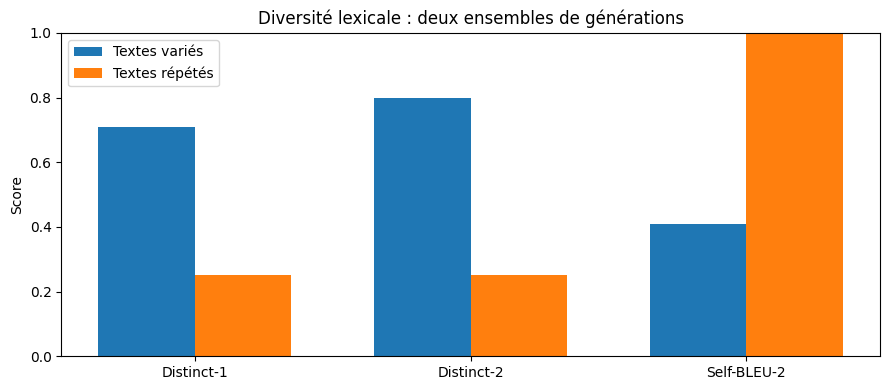

In [16]:
varied_dist1=distinct_n(generations,1)
varied_dist2=distinct_n(generations,2)
_,varied_self=self_bleu(generations,2)
repeated=['Le ciel est bleu']*4
rep_dist1=distinct_n(repeated,1)
rep_dist2=distinct_n(repeated,2)
_,rep_self=self_bleu(repeated,2)
labels=['Distinct-1','Distinct-2','Self-BLEU-2']
x=list(range(3)); width=.35
fig,ax=plt.subplots(figsize=(9,4))
ax.bar([z-width/2 for z in x],[varied_dist1,varied_dist2,varied_self],width,label='Textes variés')
ax.bar([z+width/2 for z in x],[rep_dist1,rep_dist2,rep_self],width,label='Textes répétés')
ax.set_xticks(x,labels);ax.set_ylim(0,1);ax.set_ylabel('Score');ax.set_title('Diversité lexicale : deux ensembles de générations');ax.legend()
plt.tight_layout();plt.show()

### Exercice 3
1. Modifie les probabilités du premier exemple de PPL (proches de 1, puis proches de 0). Compare la PPL.
2. Ajoute deux textes très similaires à `generations` et recalcule Distinct-n et Self-BLEU.
3. Explique pourquoi Distinct-n élevé et Self-BLEU faible ne garantissent pas un texte factuellement correct.

---
# BONUS — Évaluation humaine

Quatre dimensions notées de 1 à 5 : **Fluency (fluidité)**, **Coherence (cohérence)**, **Relevance (pertinence)**, **Factuality (exactitude factuelle)**.

| Note | Interprétation |
|--:|:--|
| 1 | Très faible : défaut majeur |
| 2 | Faible : plusieurs problèmes |
| 3 | Moyen : globalement acceptable |
| 4 | Bon : légères imperfections |
| 5 | Excellent : critère pleinement satisfait |

Il est préférable de rapporter les **quatre dimensions séparément** : la moyenne peut masquer une erreur factuelle grave.

In [17]:
human_evaluation=[
    {'texte':'La capitale du Maroc est Casablanca.', 'fluency':5,'coherence':5,'relevance':5,'factuality':1},
    {'texte':'La capitale du Maroc est Rabat.', 'fluency':5,'coherence':5,'relevance':5,'factuality':5},
]
for row in human_evaluation:
    values=[row[x] for x in ('fluency','coherence','relevance','factuality')]
    print(row['texte'])
    print('Notes:',dict(zip(('fluency','coherence','relevance','factuality'),values)),
          '| Moyenne:',statistics.mean(values))
    print('La moyenne seule peut cacher des erreurs graves.\n')

La capitale du Maroc est Casablanca.
Notes: {'fluency': 5, 'coherence': 5, 'relevance': 5, 'factuality': 1} | Moyenne: 4
La moyenne seule peut cacher des erreurs graves.

La capitale du Maroc est Rabat.
Notes: {'fluency': 5, 'coherence': 5, 'relevance': 5, 'factuality': 5} | Moyenne: 5
La moyenne seule peut cacher des erreurs graves.



---
# Bilan final — Quel indicateur choisir ?

| Tâche | Métrique | Question principale |
|:--|:--|:--|
| Résumé | ROUGE-1 | Quels mots sont communs ? |
| Résumé | ROUGE-2 | Quels bigrammes sont communs ? |
| Résumé | ROUGE-L | Quelle sous-séquence ordonnée est commune ? |
| Résumé | BLEU | Quelle précision modifiée des n-grammes, avec pénalité de longueur ? |
| Résumé | BERTScore | Les tokens sont-ils proches sémantiquement ? |
| QA | Exact Match | La réponse correspond-elle exactement ? |
| QA | Token F1 | Quels tokens correspondent partiellement ? |
| QA | Similarité sémantique | Les réponses ont-elles un sens proche ? |
| QA/RAG | Faithfulness | Les affirmations sont-elles étayées par les documents ? |
| Génération | Perplexity | Le modèle prédit-il bien les tokens réels ? |
| Génération | Distinct-n | Utilise-t-il des n-grammes variés ? |
| Génération | Self-BLEU | Ses générations se ressemblent-elles ? |
| Génération | MAUVE | Sa distribution est-elle proche de celle des textes humains ? |

## Travail à rendre (mini compte rendu)
1. Une capture des résultats de chaque partie.
2. Deux exemples où des métriques complémentaires donnent des conclusions différentes.
3. Un tableau comparatif des métriques.
4. Un paragraphe de conclusion expliquant pourquoi **aucune métrique isolée ne garantit la qualité d'un système NLP**.

### Ressources pour aller plus loin
- [ROUGE — Hugging Face Evaluate](https://github.com/huggingface/evaluate/blob/main/metrics/rouge/README.md)
- [BERTScore — dépôt officiel](https://github.com/Tiiiger/bert_score)
- [MAUVE — documentation officielle](https://krishnap25.github.io/mauve/)